# 02 — Model and imbalance-strategy comparison

Answers RQ1 using five-fold training-set cross-validation and a separate validation split. It compares six classifiers and five imbalance strategies; resampling was confined to training folds.

**Reproducibility rule:** outputs below are generated from the untouched held-out test set or from validation/CV reports; no test result is used to fit the model or choose thresholds.

In [1]:
from pathlib import Path
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (precision_recall_curve, roc_curve, auc,
                             confusion_matrix, ConfusionMatrixDisplay)

warnings.filterwarnings("ignore", category=FutureWarning)
ROOT = Path.cwd()
PUB = ROOT / "publication"
FIGURES = PUB / "figures"
TABLES = PUB / "tables"
FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({
    "figure.dpi": 120, "savefig.dpi": 300, "font.size": 10,
    "axes.titlesize": 12, "axes.labelsize": 10,
    "axes.spines.top": False, "axes.spines.right": False,
})
BLUE, GOLD, RED, GREEN, GREY = "#1f4e79", "#d89b2b", "#b03a2e", "#2e7d32", "#6b7280"

In [2]:
models = pd.read_csv(ROOT / "reports" / "model_comparison.csv").sort_values("validation_pr_auc", ascending=False)
imb = pd.read_csv(ROOT / "reports" / "imbalance_strategy_comparison.csv").sort_values("validation_pr_auc", ascending=False)
models

,model,cv_pr_auc_mean,cv_pr_auc_std,cv_roc_auc_mean,cv_roc_auc_std,validation_pr_auc,validation_roc_auc
0,hist_gradient_boosting,0.251236,0.026618,0.839355,0.007071,0.243918,0.832834
1,random_forest,0.223671,0.025811,0.826457,0.013967,0.226763,0.833051
2,extra_trees,0.228772,0.029976,0.822480,0.014430,0.220070,0.833975
3,logistic_regression,0.159794,0.027873,0.795080,0.013692,0.153160,0.797352
4,gaussian_naive_bayes,0.085403,0.019813,0.633581,0.081767,0.096174,0.679155
5,dummy_prior,0.059879,0.000210,0.500000,0.000000,0.059663,0.500000


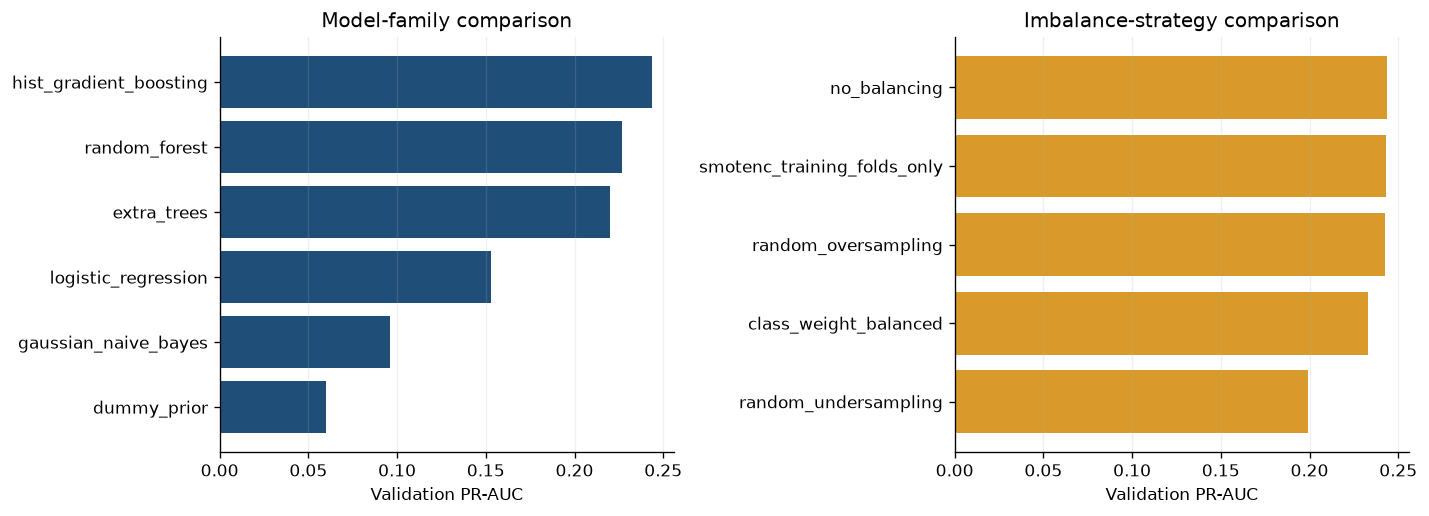

In [3]:
models.to_csv(TABLES / "table_03_model_comparison.csv", index=False)
imb.to_csv(TABLES / "table_04_imbalance_comparison.csv", index=False)
(TABLES / "table_03_model_comparison.tex").write_text(models.to_latex(index=False, escape=True, float_format="%.4f"), encoding="utf-8")
(TABLES / "table_04_imbalance_comparison.tex").write_text(imb.to_latex(index=False, escape=True, float_format="%.4f"), encoding="utf-8")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
axes[0].barh(models["model"], models["validation_pr_auc"], color=BLUE)
axes[0].invert_yaxis(); axes[0].set_xlabel("Validation PR-AUC"); axes[0].set_title("Model-family comparison")
axes[1].barh(imb["strategy"], imb["validation_pr_auc"], color=GOLD)
axes[1].invert_yaxis(); axes[1].set_xlabel("Validation PR-AUC"); axes[1].set_title("Imbalance-strategy comparison")
for ax in axes: ax.grid(axis="x", alpha=.2)
fig.tight_layout(); fig.savefig(FIGURES / "figure_02_model_imbalance_comparison.png", bbox_inches="tight"); plt.show()

The selected HistGradientBoosting model without resampling achieved the highest cross-validated and validation PR-AUC. This directly answers why the production model was not artificially balanced: balancing was tested fairly, inside training folds, and did not improve the primary validation criterion.